# 02 · Hypothesis testing: H1, H2 and H3
**BADIR stage: Analysis → Insights**

> **At a glance**
> | | Hypothesis | Result (2026, unseen data) | Verdict |
> |---|---|---|---|
> | **H1** | Counties next to Missouri (cheap spirits) buy less in Iowa | **−44%** liters per adult | Supported |
> | **H2** | More Hispanic residents → larger tequila/mezcal share | **+0.8 pts** share per +10 pts Hispanic | Supported |
> | **H3** | A new store mostly takes sales from existing stores | incumbents **−13%**; **~60%** of the newcomer's volume is diverted | Supported* |
>
> \* with one disclosed deviation (explained in section 4).

**The key idea: pre-registration.** The hypotheses and their pass/fail rules were written down in
`reports/pre_registration.md` **before** any 2026 result was computed. 2025 is the *discovery* sample (where we
spotted the patterns); Jan–Oct 2026 is the *confirmation* sample (where we test them). That stops us from
choosing hypotheses after seeing the answer.

**Contents**
1. The testing toolkit (each method explained)
2. H1 · Cross-border leakage
3. H2 · Ethnic composition and agave share
4. H3 · Do new stores create demand or move it?
5. Verdicts and association vs causation

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import logging; logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
from abd_demand import config as C, plotting as P, hypotheses as H   # H = the test functions

P.use_style()
pd.set_option("display.width", 170)
pd.set_option("display.float_format", "{:,.4f}".format)

county = pd.read_parquet(C.PROCESSED / "county_period.parquet")      # 99 counties x 3 periods
county["log_dollars_per_adult"] = np.log(county.dollars_per_adult)

# Every county test controls for these four things, so a result is not just "big / rich / old / educated counties differ"
CONTROLS = ["log_population", "income_k", "cty_median_age", "cty_pct_bachelors_or_higher"]

## 1. The testing toolkit
Each county-level hypothesis is tested **five ways**. It counts as *supported* only if it passes all of them.

| Method | What it is, simply | Why we use it |
|---|---|---|
| **OLS regression with controls** | Fits outcome = a + b × (variable of interest) + c × (controls). *b* is the effect with the controls held fixed. | Separates the border effect from, say, "border counties are poorer". |
| **HC3 robust standard errors** | A way of computing the uncertainty of *b* that does not assume every county is equally noisy. | Counties range from 4,000 to 500,000 people; small ones are much noisier. |
| **Permutation test (Freedman–Lane)** | Shuffle the data 5,000 times so that, by construction, there is no real effect; count how often a shuffle gives a result as strong as the real one. That share is the p-value. | Needs no assumption that errors are normally distributed. |
| **Bootstrap confidence interval** | Resample the 99 counties with replacement 2,000 times, refit each time, take the middle 95% of estimates. | A range for the effect size that also needs no normality assumption. |
| **Influence check (Cook's distance)** | Drop counties whose removal changes the fit a lot (Cook's D > 4/n), then refit. | A result must not hinge on one or two unusual counties. |
| **Population weights** | Refit giving each county weight in proportion to its adults. | Unweighted = the typical *county*; weighted = the typical *person*. A result must hold both ways. |

**Reading a p-value.** If there were truly no effect, how often would we see a result this strong by chance?
p < 0.05 means "less than 5% of the time", our threshold for significance. Tests are **one-sided**: the direction
was stated in advance (e.g. border counties buy *less*).

## 2. H1 · Cross-border leakage
> **Hypothesis.** Counties where cheaper out-of-state spirits are close by buy fewer liters per adult from Iowa stores.

**Why we expect it.** Iowa's implied spirits tax is **\$15.14 per gallon**; Missouri's is **\$2.00**, the lowest of all
neighbours. Sales are recorded where the *store* is, so a resident who buys in Missouri never shows up in Iowa's data.

H1 has four parts: **H1a** (the main test: border with Missouri), **H1b** (a dose-response: does a bigger tax gap mean
fewer liters?), **H1c** (a fingerprint: fewer 1.75 L "stock-up" bottles), **H1d** (an alternative explanation: leakage to a
bigger Iowa neighbour). We also re-test H1a in **dollars**, which the multi-pack mini issue cannot affect.

In [2]:
# name: (variable of interest, outcome, controls, expected sign: -1 = negative)
TESTS = {
    "H1a  Missouri border -> liters/adult":       ("geo_borders_mo",     "log_liters_per_adult",  CONTROLS, -1),
    "H1b  tax gap -> liters/adult":               ("geo_border_tax_gap", "log_liters_per_adult",  CONTROLS, -1),
    "H1c  Missouri border -> 1.75 L share":       ("geo_borders_mo",     "handle_share",          CONTROLS, -1),
    "H1d  bigger Iowa neighbour -> liters/adult": ("geo_log_hub_ratio",  "log_liters_per_adult",  CONTROLS, -1),
    "H1a' Missouri border -> dollars/adult":      ("geo_borders_mo",     "log_dollars_per_adult", CONTROLS, -1),
    "H2   % Hispanic -> agave share":             ("cty_pct_hispanic",   "agave_share", ["log_population", "income_k"], +1),
}

rows = []
for period in ["FY2025", "JanOct2026"]:                      # discovery year, then confirmation year
    data = county[county.period == period]
    for name, (x, y, controls, sign) in TESTS.items():
        result = H.county_test(data, x, y, controls, sign, n_perm=5000, n_boot=2000)
        rows.append({"test": name, "period": period, **result})
results = pd.DataFrame(rows)

readable = results.rename(columns={
    "coef": "effect", "p_hc3": "p (HC3)", "p_perm": "p (permutation)", "boot_ci_low": "CI low",
    "boot_ci_high": "CI high", "p_trimmed": "p (no outliers)", "p_weighted": "p (pop. weighted)"})
readable[["test", "period", "effect", "p (HC3)", "p (permutation)", "CI low", "CI high",
          "p (no outliers)", "p (pop. weighted)", "supported"]]

,test,period,effect,p (HC3),p (permutation),CI low,CI high,p (no outliers),p (pop. weighted),supported
0,H1a Missouri border -> liters/adult,FY2025,-0.5586,0.0003,0.0002,-0.8587,-0.2376,0.0000,0.0322,True
1,H1b tax gap -> liters/adult,FY2025,-0.0217,0.0055,0.0028,-0.0375,-0.0049,0.0170,0.2876,False
2,H1c Missouri border -> 1.75 L share,FY2025,-0.0888,0.0076,0.0012,-0.1585,-0.0252,0.0000,0.0555,False
3,H1d bigger Iowa neighbour -> liters/adult,FY2025,-0.0574,0.0989,0.0984,-0.1407,0.0323,0.0363,0.0450,False
4,H1a' Missouri border -> dollars/adult,FY2025,-0.4846,0.0010,0.0002,-0.7789,-0.1806,0.0000,0.0623,False
5,H2 % Hispanic -> agave share,FY2025,0.0006,0.0001,0.0016,0.0003,0.0009,0.0000,0.0125,True
6,H1a Missouri border -> liters/adult,JanOct2026,-0.5847,0.0001,0.0002,-0.8764,-0.2889,0.0000,0.0008,True
7,H1b tax gap -> liters/adult,JanOct2026,-0.0222,0.0051,0.0030,-0.0385,-0.0053,0.0089,0.2145,False
8,H1c Missouri border -> 1.75 L share,JanOct2026,-0.0724,0.0452,0.0074,-0.1559,-0.0023,0.0007,0.2316,False
9,H1d bigger Iowa neighbour -> liters/adult,JanOct2026,-0.0603,0.0959,0.0998,-0.1461,0.0320,0.0422,0.0502,False


**How to read the table.** `effect` is the regression coefficient. For liters per adult the outcome is in logs,
so an effect of −0.58 means exp(−0.58) − 1 ≈ **−44%**. `supported` is True only if all four p-values are below 0.05.

In [3]:
h1 = results[(results.test.str.startswith("H1a ")) & (results.period == "JanOct2026")].iloc[0]
effect_pct = 100 * (np.exp(h1.coef) - 1)
ci_low_pct, ci_high_pct = 100 * (np.exp(h1.boot_ci_low) - 1), 100 * (np.exp(h1.boot_ci_high) - 1)
print(f"H1a, 2026: Missouri-border counties buy {abs(effect_pct):.0f}% fewer liters per adult than comparable counties "
      f"(95% bootstrap CI {abs(ci_high_pct):.0f}% to {abs(ci_low_pct):.0f}% fewer)")

H1a, 2026: Missouri-border counties buy 44% fewer liters per adult than comparable counties (95% bootstrap CI 25% to 58% fewer)


**The picture.** Median liters per adult for counties grouped by which state they touch (left), and how the
shortfall fades with distance from Missouri (right).

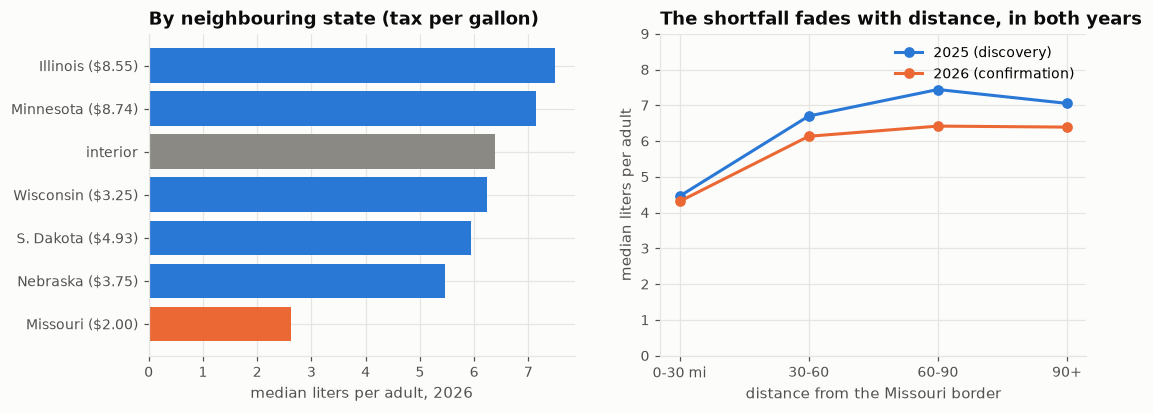

In [4]:
d26 = county[county.period == "JanOct2026"].copy()
d26["neighbour"] = np.select(
    [d26.geo_borders_mo == 1, d26.geo_borders_wi == 1, d26.geo_borders_ne == 1,
     d26.geo_borders_sd == 1, d26.geo_borders_il == 1, d26.geo_borders_mn == 1],
    ["Missouri ($2.00)", "Wisconsin ($3.25)", "Nebraska ($3.75)", "S. Dakota ($4.93)", "Illinois ($8.55)", "Minnesota ($8.74)"],
    "interior")
by_neighbour = d26.groupby("neighbour").liters_per_adult.median().sort_values()

county["distance_band"] = pd.cut(county.geo_miles_to_mo_border, [0, 30, 60, 90, 250],
                                 labels=["0-30 mi", "30-60", "60-90", "90+"])
gradient = county.groupby(["period", "distance_band"], observed=True).liters_per_adult.median().unstack(0)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
colors = [P.ORANGE if n.startswith("Missouri") else P.MUTED if n == "interior" else P.BLUE for n in by_neighbour.index]
axes[0].barh(by_neighbour.index, by_neighbour.values, color=colors)
axes[0].set_xlabel("median liters per adult, 2026"); axes[0].set_title("By neighbouring state (tax per gallon)")
axes[1].plot(gradient.index.astype(str), gradient["FY2025"], marker="o", color=P.BLUE, label="2025 (discovery)")
axes[1].plot(gradient.index.astype(str), gradient["JanOct2026"], marker="o", color=P.ORANGE, label="2026 (confirmation)")
axes[1].set_ylim(0, 9); axes[1].set_xlabel("distance from the Missouri border"); axes[1].set_ylabel("median liters per adult")
axes[1].set_title("The shortfall fades with distance, in both years"); axes[1].legend()
P.save(fig, "h1_border"); plt.show()

### What is at stake for the state?
If the Missouri-border counties bought at the rate predicted for comparable counties, how much more would Iowa stores
sell? This is an **upper bound**: part of the gap may be lower drinking, not purchases in Missouri.

In [5]:
sales = pd.read_parquet(C.SSOT, columns=["year", "state_bottle_cost", "state_bottle_retail", "sales_bottles"])
sales = sales[(sales.year == 2026) & (sales.sales_bottles > 0) & sales.state_bottle_cost.notna()]
cost = (sales.state_bottle_cost * sales.sales_bottles).sum()
retail = (sales.state_bottle_retail * sales.sales_bottles).sum()
abd_margin = 1 - cost / retail                                   # ABD's gross margin on sales to stores
del sales

border26 = d26[d26.geo_borders_mo == 1]
uplift = np.exp(-h1.coef) - 1                                    # how much more they would buy without the gap
missing_sales = (border26.dollars * 12 / 10).sum() * uplift      # annualise Jan-Oct to 12 months
print(f"ABD gross margin: {100 * abd_margin:.1f}%")
print(f"Sales missing in Missouri-border counties: ${missing_sales / 1e6:.1f}M a year")
print(f"ABD margin at stake: ${missing_sales * abd_margin / 1e6:.1f}M a year (upper bound)")

ABD gross margin: 33.4%
Sales missing in Missouri-border counties: $5.9M a year
ABD margin at stake: $2.0M a year (upper bound)


> **H1 verdict**
> * **H1a: supported.** Missouri-border counties buy **~44% fewer liters per adult** in 2026, almost exactly the 2025
>   estimate, and pass all four checks. It also holds in **dollars**, so it is not an artefact of how liters are recorded.
> * **H1b (tax-gap dose-response): inconclusive.** Passes three checks but not population weighting.
> * **H1c (fewer 1.75 L bottles): inconclusive.** Same pattern.
> * **H1d (leakage to a bigger Iowa neighbour): not supported** (p ≈ 0.10).
>
> **Decision relevance.** Per-adult planning norms over-state demand along the southern border, and the state loses
> roughly \$2M of margin a year (upper bound) to the price gap. Briefing material for ABD's board and the legislature.

## 3. H2 · Ethnic composition and agave share
> **Hypothesis.** Counties with a larger Hispanic population buy a larger share of tequila and mezcal (agave),
> controlling for population and income.

Carried over from the pre-submission (where it was found on 2025 data) and now confirmed on 2026.

In [6]:
h2 = readable[readable.test.str.startswith("H2")]
h2[["test", "period", "effect", "p (HC3)", "p (permutation)", "p (no outliers)", "p (pop. weighted)", "supported"]]

,test,period,effect,p (HC3),p (permutation),p (no outliers),p (pop. weighted),supported
5,H2 % Hispanic -> agave share,FY2025,0.0006,0.0001,0.0016,0.0000,0.0125,True
11,H2 % Hispanic -> agave share,JanOct2026,0.0008,0.0004,0.0006,0.0000,0.0238,True


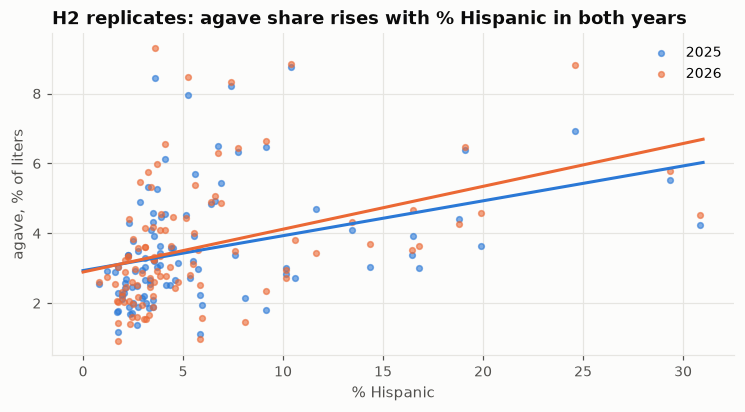

2026: +10 points of Hispanic population -> +0.81 points of agave share


In [7]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for period, color, label in [("FY2025", P.BLUE, "2025"), ("JanOct2026", P.ORANGE, "2026")]:
    d = county[county.period == period]
    ax.scatter(d.cty_pct_hispanic, 100 * d.agave_share, s=14, color=color, alpha=0.6, label=label)
    slope, intercept = np.polyfit(d.cty_pct_hispanic, 100 * d.agave_share, 1)   # straight trend line
    xs = np.linspace(0, 31, 20)
    ax.plot(xs, intercept + slope * xs, color=color)
ax.set_xlabel("% Hispanic"); ax.set_ylabel("agave, % of liters"); ax.legend()
ax.set_title("H2 replicates: agave share rises with % Hispanic in both years")
P.save(fig, "h2_agave"); plt.show()

h2_2026 = results[(results.test.str.startswith("H2")) & (results.period == "JanOct2026")].iloc[0]
print(f"2026: +10 points of Hispanic population -> +{100 * 10 * h2_2026.coef:.2f} points of agave share")

> **H2 verdict: supported** (all four checks, both years). The effect is moderate: +10 points of Hispanic population
> goes with ~+0.8 points of agave share, against an average share of ~3.6%.
>
> **Decision relevance.** Sets the agave *assortment* for each delivery region. It describes counties, not people
> (the *ecological fallacy*: we never say "Hispanic individuals drink tequila"), and ethnicity is kept out of the
> forecast model (notebook 04).

## 4. H3 · Do new stores create demand or move it?
> **Hypothesis.** When a new store opens in a city, the stores already there (*incumbents*) order less, so the city's
> total grows by less than the newcomer sells.

### The method: difference-in-differences (DiD)
A simple before/after comparison would mix the new store's effect with everything else that changed (season, the
−3% market). DiD subtracts out those common changes using a control group:

```
                          before entry    after entry    change
incumbents, city WITH a new store   100            85          −15   ┐
incumbents, cities WITHOUT entry    100            98           −2   ┘  difference of the differences = −13
```

* **Treated group:** incumbent stores in a city that gets its first genuinely new store in month *g*.
* **Control group:** incumbents in cities with no new store or closure within six months either side.
* **Stacked:** entries happen in different months, so we build one clean comparison ("stack") per entry month
  and pool them. A plain regression would wrongly use already-affected stores as controls.
* **Fixed effects:** each store's own average level and each month's statewide level are removed, so we compare
  changes, not levels.
* **Key assumption (parallel trends):** without the entry, both groups would have moved together. We check it by
  testing that the two groups moved together *before* the entry (the "pre-trend" test).
* **Placebo:** a new owner taking over an existing shop is not new competition, so it should show **no** effect.

**Outcomes.** log(1 + liters) and liters were pre-registered. Raw liters turned out to be dominated by a few
giant stores, so we also report **liters relative to each store's own pre-entry average**. That is a deviation from
the pre-registration, and we disclose it.

In [8]:
store_month = pd.read_parquet(C.PROCESSED / "store_month.parquet")
stores = pd.read_parquet(C.STORE_DIM)

new_store_stacks = H.build_stacks(store_month, stores, "new_store")          # treated: genuinely new stores
placebo_stacks   = H.build_stacks(store_month, stores, "ownership_change")   # placebo: new owner, same shop

designs = [
    ("new store: log(1+L)",               new_store_stacks, "log_liters"),
    ("new store: liters",                 new_store_stacks, "liters"),
    ("new store: L / own pre-entry mean", new_store_stacks[new_store_stacks.liters_norm.notna()], "liters_norm"),
    ("PLACEBO owner change: log(1+L)",    placebo_stacks, "log_liters"),
    ("PLACEBO owner change: L / own pre-entry mean", placebo_stacks[placebo_stacks.liters_norm.notna()], "liters_norm"),
]
rows, event_studies = [], {}
for label, data, outcome in designs:
    r = H.stacked_did(data, outcome=outcome)
    event_studies[label] = r["event_study"]
    rows.append({"design": label, "effect (ATT)": r["att"], "CI low": r["ci"][0], "CI high": r["ci"][1],
                 "p": r["p"], "pre-trend p": r["pretrend_p"], "treated stores": r["n_treated_units"],
                 "treated cities": r["n_treated_cities"]})
did = pd.DataFrame(rows)
did

,design,effect (ATT),CI low,CI high,p,pre-trend p,treated stores,treated cities
0,new store: log(1+L),-0.2320,-0.3031,-0.1608,0.0000,0.1099,1136,116
1,new store: liters,6.9321,-14.6736,28.5377,0.5295,0.9434,1136,116
2,new store: L / own pre-entry mean,-0.1324,-0.2332,-0.0317,0.0100,0.9669,1136,116
3,PLACEBO owner change: log(1+L),-0.0336,-0.1482,0.0809,0.5649,0.0001,163,20
4,PLACEBO owner change: L / own pre-entry mean,-0.0211,-0.0719,0.0296,0.4140,0.0000,163,20


**How to read it.** `effect (ATT)` = average effect on the treated incumbents. On the normalised outcome, −0.13
means incumbents fall to 87% of their own pre-entry level. `pre-trend p` > 0.05 means the groups moved together
*before* entry, which supports the parallel-trends assumption.

### Event study: the effect month by month
Instead of one before/after number, estimate the gap separately for each month around the entry. Before entry the
dots should sit on zero; after entry they show how the effect builds up.

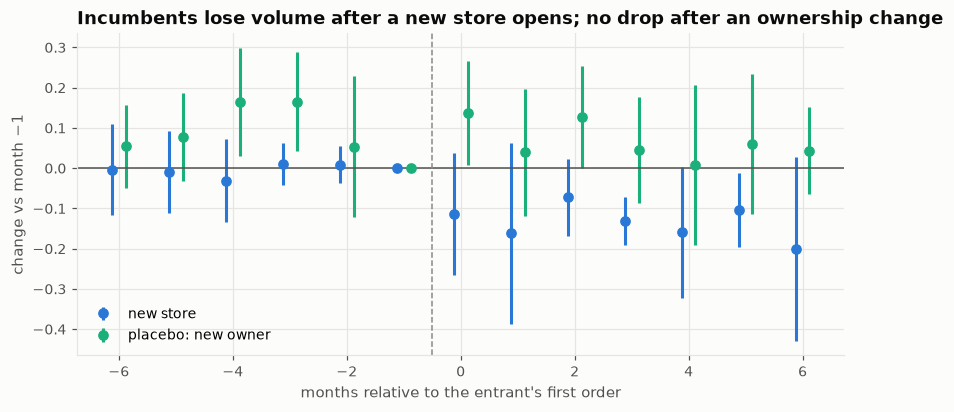

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.8))
series = [("new store: L / own pre-entry mean", P.BLUE, "new store", -0.12),
          ("PLACEBO owner change: L / own pre-entry mean", P.AQUA, "placebo: new owner", 0.12)]
for label, color, legend, shift in series:
    es = event_studies[label]
    ax.errorbar(es.event_time + shift, es.coef, yerr=1.96 * es.se, fmt="o", color=color, capsize=0, label=legend)
ax.axhline(0, color=P.INK2, lw=1)
ax.axvline(-0.5, color=P.MUTED, ls="--", lw=1)
ax.set_xlabel("months relative to the entrant's first order"); ax.set_ylabel("change vs month −1")
ax.set_title("Incumbents lose volume after a new store opens; no drop after an ownership change")
ax.legend(loc="lower left")
P.save(fig, "h3_event_study"); plt.show()

### Diversion ratio: how much of the newcomer's volume is stolen?
**Diversion ratio = incumbents' lost liters ÷ the newcomer's liters.** 100% means the city sells no more than before (pure
reshuffling); 0% means every liter the newcomer sells is new demand. We compute it at city level, and get a
confidence interval with a **cluster bootstrap** (resample whole cities, 200 times).

In [10]:
city = H.city_level(new_store_stacks)
incumbent_effect = H.stacked_did(city, outcome="incumbent_norm")
total_effect     = H.stacked_did(city, outcome="total_norm")
entrant_share = city[(city.treated == 1) & (city.event_time >= 0)].entrant_norm.mean()
diversion = -incumbent_effect["att"] / entrant_share

rng = np.random.default_rng(C.SEED)
cities = city.city_key.unique()
boot = []
for _ in range(200):
    picked = rng.choice(cities, len(cities), replace=True)
    sample = pd.concat([city[city.city_key == c].assign(unit=lambda x, i=i: x.unit + f"#{i}")
                        for i, c in enumerate(picked)], ignore_index=True)
    if sample.treated.nunique() < 2:
        continue
    att = H.stacked_did(sample, outcome="incumbent_norm")["att"]
    entrant = sample[(sample.treated == 1) & (sample.event_time >= 0)].entrant_norm.mean()
    boot.append(-att / entrant)
low, high = np.percentile(boot, [2.5, 97.5])

print(f"Incumbents: {100 * incumbent_effect['att']:+.1f}% of the city's pre-entry volume (p={incumbent_effect['p']:.3f})")
print(f"City total: {100 * total_effect['att']:+.1f}% (p={total_effect['p']:.3f}); the newcomer adds {100 * entrant_share:.1f}%")
print(f"DIVERSION RATIO: {100 * diversion:.0f}% (95% CI {100 * low:.0f}% to {100 * high:.0f}%) -> about {100 * (1 - diversion):.0f}% is new demand")

Incumbents: -21.8% of the city's pre-entry volume (p=0.008)
City total: +15.5% (p=0.130); the newcomer adds 36.2%
DIVERSION RATIO: 60% (95% CI 28% to 129%) -> about 40% is new demand


### Who loses most? Small vs large incumbents

In [11]:
median_size = new_store_stacks.groupby("unit").pre_mean.first().median()
rows = []
for label, mask in [("small incumbents", new_store_stacks.pre_mean <= median_size),
                    ("large incumbents", new_store_stacks.pre_mean > median_size)]:
    data = new_store_stacks[mask & new_store_stacks.liters_norm.notna()]
    r = H.stacked_did(data, outcome="liters_norm")
    rows.append({"group": label, "effect": r["att"], "CI low": r["ci"][0], "CI high": r["ci"][1], "p": r["p"]})
pd.DataFrame(rows)

,group,effect,CI low,CI high,p
0,small incumbents,-0.2066,-0.3714,-0.0417,0.0140
1,large incumbents,-0.0426,-0.0684,-0.0168,0.0012


> **H3 verdict: supported, with one disclosed deviation.**
> * Incumbents fall by **~13%** of their own pre-entry level after a genuinely new store opens (p ≈ 0.01), and the
>   pre-trend test is clean (p ≈ 0.97). On log(1+L), the pre-registered outcome, the fall is ~−23% (p < 0.001).
> * On raw liters (pre-registered) it is not significant: a few giant stores dominate. Hence the normalised outcome,
>   reported as a deviation.
> * **Placebo:** no post-change effect (≈ −2%, p ≈ 0.41), but its pre-period is noisy (only 20 cities), so it supports
>   the design without proving it.
> * **Diversion ≈ 60%** (CI ≈ 28%–129%): most of a new store's volume is taken from existing stores.
> * **Small incumbents bear most of the loss** (≈ −21% vs ≈ −4% for large ones).
>
> **Decision relevance.** Plan a new licence at well under 100% net new volume and cut its neighbours' plans.
> For licensing: most entry reshuffles sales rather than raising consumption, but small independents are at risk.

## 5. Verdicts in one table

In [12]:
v = results[results.period == "JanOct2026"].set_index("test")
att_norm = did.loc[did.design == "new store: L / own pre-entry mean", "effect (ATT)"].iloc[0]
summary = pd.DataFrame([
    ["H1a", "Missouri border -> fewer liters/adult", f"{100 * (np.exp(v.loc['H1a  Missouri border -> liters/adult', 'coef']) - 1):.0f}%", "SUPPORTED (4/4 checks, both years; also in $)"],
    ["H1b", "tax-gap dose-response", f"{v.loc['H1b  tax gap -> liters/adult', 'coef']:.3f} log per $", "INCONCLUSIVE (fails population weighting)"],
    ["H1c", "fewer 1.75 L bottles at the MO border", f"{100 * v.loc['H1c  Missouri border -> 1.75 L share', 'coef']:.1f} pts", "INCONCLUSIVE (fails population weighting)"],
    ["H1d", "bigger Iowa neighbour -> fewer liters", f"{v.loc['H1d  bigger Iowa neighbour -> liters/adult', 'coef']:.3f}", "NOT SUPPORTED (p ~ 0.10)"],
    ["H2", "% Hispanic -> agave share", f"+{100 * 10 * v.loc['H2   % Hispanic -> agave share', 'coef']:.2f} pts per +10 pts", "SUPPORTED (4/4 checks, both years)"],
    ["H3", "new licence -> incumbents order less", f"{100 * att_norm:.0f}%; diversion {100 * diversion:.0f}% (CI {100 * low:.0f}-{100 * high:.0f}%)", "SUPPORTED (clean pre-trend; disclosed deviation)"],
], columns=["id", "hypothesis", "2026 effect", "verdict"])

TABLES = C.ROOT / "reports" / "tables"
summary.to_csv(TABLES / "hypothesis_verdicts.csv", index=False)
results.to_csv(TABLES / "county_tests.csv", index=False)
did.to_csv(TABLES / "did_results.csv", index=False)
summary

,id,hypothesis,2026 effect,verdict
0,H1a,Missouri border -> fewer liters/adult,-44%,"SUPPORTED (4/4 checks, both years; also in $)"
1,H1b,tax-gap dose-response,-0.022 log per $,INCONCLUSIVE (fails population weighting)
2,H1c,fewer 1.75 L bottles at the MO border,-7.2 pts,INCONCLUSIVE (fails population weighting)
3,H1d,bigger Iowa neighbour -> fewer liters,-0.060,NOT SUPPORTED (p ~ 0.10)
4,H2,% Hispanic -> agave share,+0.81 pts per +10 pts,"SUPPORTED (4/4 checks, both years)"
5,H3,new licence -> incumbents order less,-13%; diversion 60% (CI 28-129%),SUPPORTED (clean pre-trend; disclosed deviation)


### Association vs causation
* **H1 and H2 are associations** across 99 counties. Controls, permutation tests and replication on new data make
  them robust, but do not prove that Missouri prices *cause* the shortfall: something else linked to the southern
  border could contribute. Data from the Missouri side would allow a stronger design, but none is public.
* **H3 is a causal design** (difference-in-differences). It rests on parallel trends, which the flat pre-entry months
  and the placebo support. Entrants choose growing towns, which would bias the estimate *toward zero*, so the 60%
  diversion is, if anything, conservative.

**Next:** notebook 03 turns these findings into a forecast; notebook 05 tests 20 further, exploratory hypotheses.